In [ ]:
#import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report,roc_auc_score,roc_curve

In [ ]:
#Load the dataset
df=pd.read_csv('/content/car_evaluation.csv')
df.head()

,vhigh,vhigh.1,2,2.1,small,low,unacc
0,vhigh,vhigh,2,2,small,med,unacc
1,vhigh,vhigh,2,2,small,high,unacc
2,vhigh,vhigh,2,2,med,low,unacc
3,vhigh,vhigh,2,2,med,med,unacc
4,vhigh,vhigh,2,2,med,high,unacc


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1727 entries, 0 to 1726
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   vhigh    1727 non-null   object
 1   vhigh.1  1727 non-null   object
 2   2        1727 non-null   object
 3   2.1      1727 non-null   object
 4   small    1727 non-null   object
 5   low      1727 non-null   object
 6   unacc    1727 non-null   object
dtypes: object(7)
memory usage: 94.6+ KB


In [ ]:
df.shape

(1727, 7)

In [ ]:
df.describe()

,vhigh,vhigh.1,2,2.1,small,low,ununacc
count,1727,1727,1727,1727,1727,1727,1727
unique,4,4,4,3,3,3,3
top,high,high,3,4,med,med,ununacc
freq,432,432,432,576,576,576,1209


In [ ]:
df.isnull().sum()

,0
vhigh,0
vhigh.1,0
2,0
2.1,0
small,0
low,0
unacc,0


In [ ]:
print("NO of duplicate recors:",df.duplicated().sum())

NO of duplicate recors: 0


In [ ]:
#feature summary
numerical_features = df.select_dtypes(include=['int64','float64']).columns
categorical_features = df.select_dtypes(include=['object', 'category']).columns
print("Numerical Features:")
for col in numerical_features:
  print("-",col)
print("\nCategorical Features:")
for col in categorical_features:
  print("-",col)

Numerical Features:

Categorical Features:
- vhigh
- vhigh.1
- 2
- 2.1
- small
- low
- unacc


In [ ]:
# Rename columns to standard dataset names
df.columns = [
    'buying',
    'maint',
    'doors',
    'persons',
    'lug_boot',
    'safety',
    'class',
]

In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

# Option A: Loop through all columns in the DataFrame
for col in df.columns:
  df[col] = le.fit_transform(df[col])

In [ ]:
#target column encoding
df['class']=le.fit_transform(df['class'])
print("Target column loded succesfully")

Target column loded succesfully


In [ ]:
#separte Features and target
x = df.iloc[:,:-1]
y = df.iloc[:,-1]

In [ ]:
#split the dataset into training and testing
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [ ]:
#model building
model=DecisionTreeClassifier(criterion='entropy')
model.fit(x_train,y_train)

DecisionTreeClassifier(criterion='entropy')

In [ ]:
#predictions on test data
y_pred=model.predict(x_test)

In [ ]:
#evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)
print("Accuracy:", accuracy)
print("Confusion Matrix:",conf_matrix)
classification_rep = classification_report(y_test, y_pred)
print("Classification Report:",classification_rep)

Accuracy: 0.9913294797687862
Confusion Matrix: [[ 31   1]
 [  2 312]]
Classification Report:               precision    recall  f1-score   support

           0       0.94      0.97      0.95        32
           1       1.00      0.99      1.00       314

    accuracy                           0.99       346
   macro avg       0.97      0.98      0.97       346
weighted avg       0.99      0.99      0.99       346



In [ ]:
#training accuracy
y_train_pred=model.predict(x_train)
train_accuracy=accuracy_score(y_train,y_train_pred)
print("Training accuracy:",train_accuracy)
y_test_pred=model.predict(x_test)
test_accuracy=accuracy_score(y_test,y_test_pred)
print("Testing accuracy:",test_accuracy)

Training accuracy: 1.0
Testing accuracy: 0.9913294797687862


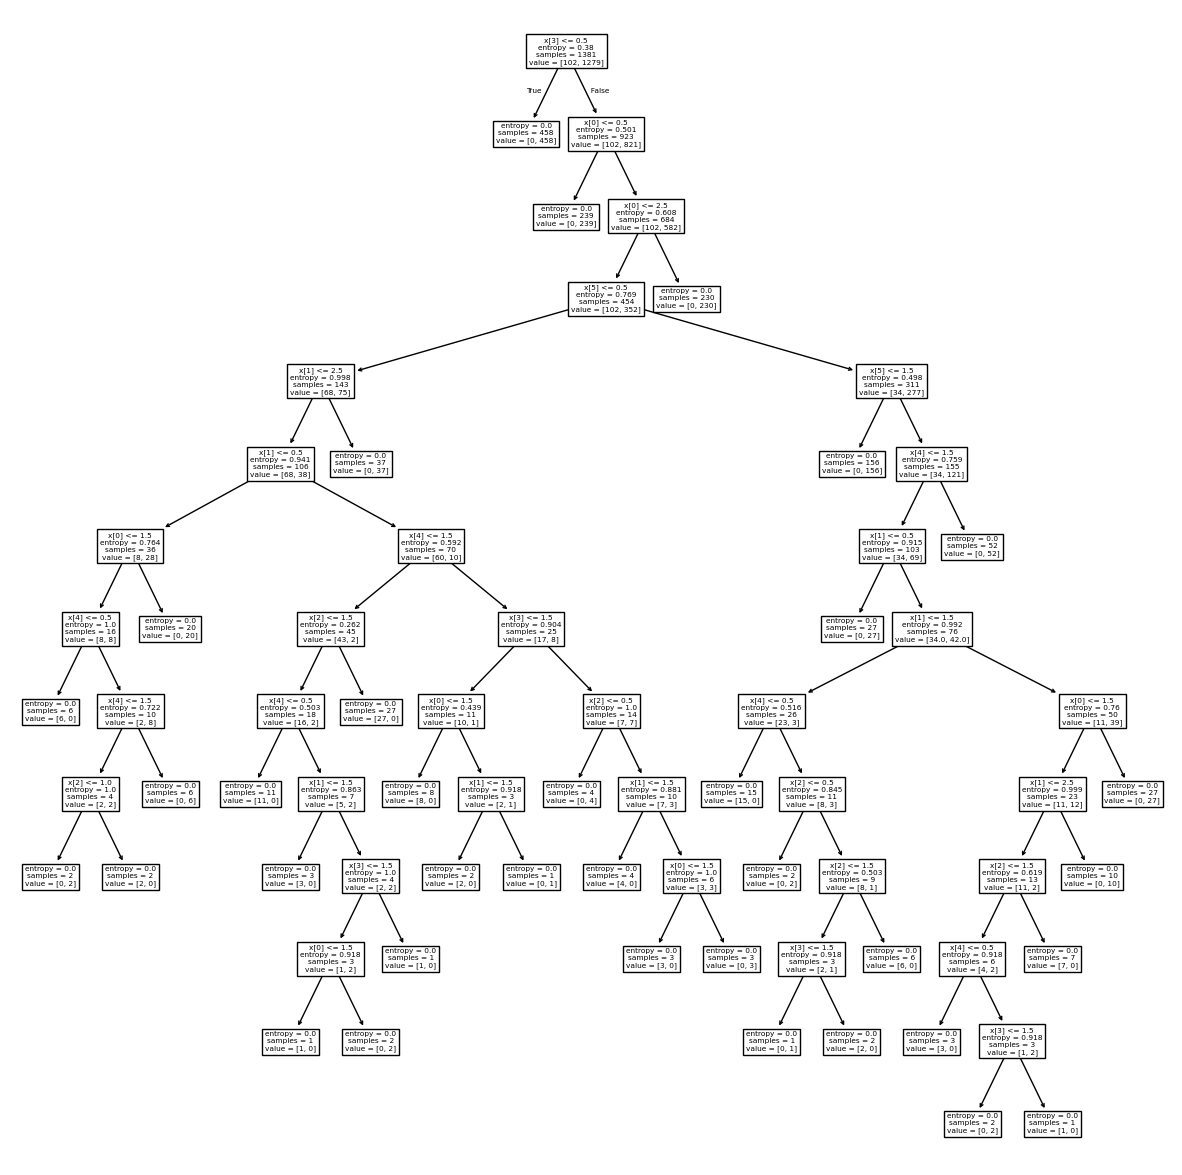

In [ ]:
#display decison tree
from sklearn.tree import plot_tree
plt.figure(figsize=(15,15))
plot_tree(model)
plt.show()

In [ ]:
#auc
auc=roc_auc_score(y_test,y_pred)
print("AUC:",auc)

AUC: 0.9811902866242038


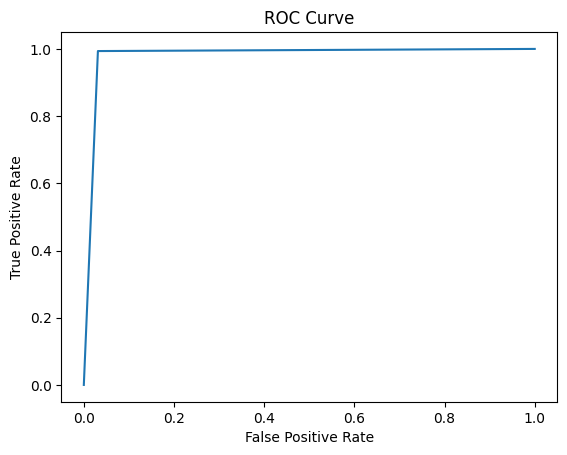

In [ ]:
#roc_curve
fpr,tpr,thresholds=roc_curve(y_test,y_pred)
plt.plot(fpr,tpr)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.show()